# Distributed Deutsch-Jozsa Simulation Using Virtual CNOT (LO + QPD) and Zero Noise Extrapolation

### Overview of the Experiment

In the original paper, a monolithic quantum circuit is partitioned across multiple quantum processing units (QPUs), and cross-partition CNOT gates are executed using shared entangled Bell pairs and quantum teleportation. That approach requires physical quantum interconnects and extra communication ancilla qubits for each cut, and the author observed that **Local ZNE** (mitigating each partition independently after cutting) performed worse than **Global ZNE** (mitigating the monolithic circuit before cutting) because teleportation errors propagate across partition boundaries.

### What I Did Differently Here
Instead of using Bell pairs and quantum teleportation, I replaced every cross-partition CNOT gate with a **Virtual CNOT gate** constructed via **Quasi-Probability Decomposition (QPD)** using only **Local Operations (LO) and Mid-Circuit Measurements (MCMs)**.
1. Each cross-partition $\text{CNOT}(q_c, q_t) = (I \otimes H)\,\text{CZ}(q_c, q_t)\,(I \otimes H)$ is decomposed into **6 local channels** consisting only of single-qubit $H$ and $R_z(\pm\pi/2, -\pi, 0)$ rotations and projective $Z$-basis mid-circuit measurements, weighted by QPD coefficients $\gamma_c = \left[+\frac{1}{2}, +\frac{1}{2}, -\frac{1}{2}, +\frac{1}{2}, -\frac{1}{2}, +\frac{1}{2}\right]$.
2. If a partitioned circuit has $K$ cross-partition CNOT gates, I generated all $6^K$ completely disconnected sub-circuits with **zero ancilla qubit overhead**, execute them, and classically recombine their expectation values $\langle Z^{\otimes (n-1)} \rangle$.
3. I applied a realistic two-tier noise model—depolarizing gate error $p_{\text{Local}}$ on all local gates and amplified error $p_{\text{comm}} = \alpha \cdot p_{\text{Local}}$ on the mid-circuit measurements—and compare **Global ZNE** (unitary gate folding before QPD cutting) against **Local ZNE** (unitary gate folding within each QPU partition after QPD cutting).

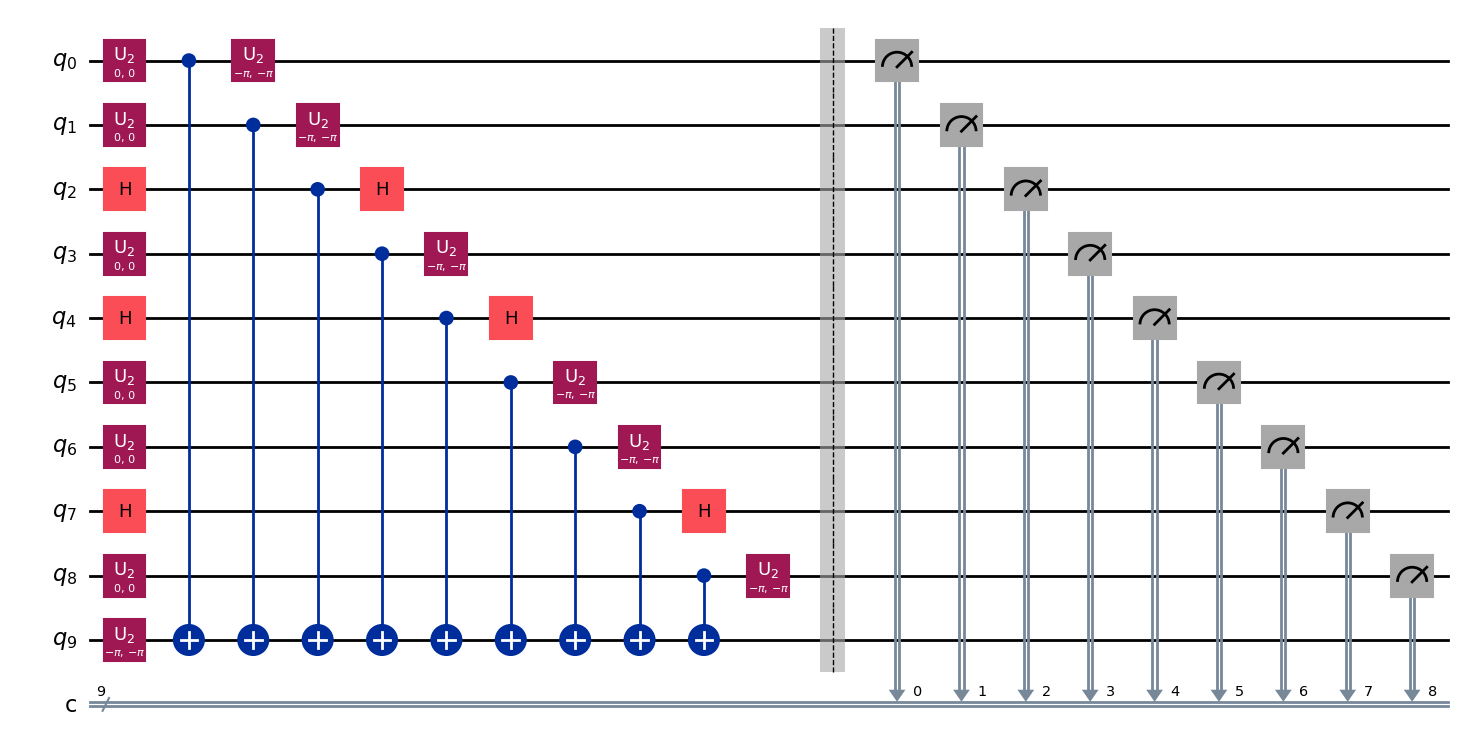

In [1]:
import numpy as np
import networkx as nx
from itertools import product
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit import transpile

# Cell 1: Load the MQT-Bench 10-qubit Deutsch-Jozsa circuit from the QASM file.
# Qubits q_0 to q_8 are the 9 query qubits (measured at the end into register `c`),
# and q_9 is the shared oracle target ancilla qubit.

qasm_path = "MQTBench_reduced/dj_indep_qiskit_10.qasm"

dj_circuit = QuantumCircuit.from_qasm_file(qasm_path)
display(dj_circuit.draw(output='mpl'))

In [2]:
# Cell 2: Partition the circuit's qubits across k = 2 QPUs using greedy modularity
# community detection on the 2-qubit gate interaction graph.
# Identifies which CNOT gates stay local within a single QPU vs. which CNOT gates
# cross between Partition 0 and Partition 1 (requiring QPD cuts).

def partition_qubits_greedy(qc, k_partitions=2):
    #Build interaction graph where nodes = qubits, edges = 2-qubit gates
    G = nx.Graph()
    G.add_nodes_from(range(qc.num_qubits))

    for inst in qc.data:
        if len(inst.qubits) == 2:
            q0 = qc.find_bit(inst.qubits[0]).index
            q1 = qc.find_bit(inst.qubits[1]).index
            if G.has_edge(q0, q1):
                G[q0][q1]['weight'] += 1
            else:
                G.add_edge(q0, q1, weight=1)

    #Find greedy modularity communities
    comms = [sorted(list(c)) for c in nx.community.greedy_modularity_communities(G, weight='weight')]

    #Adjust number of communities to match k_partitions
    while len(comms) > k_partitions:
        comms.sort(key=len)
        comms = [comms[0] + comms[1]] + comms[2:]
    while len(comms) < k_partitions:
        comms.sort(key=len, reverse=True)
        largest = comms[0]
        mid = len(largest) // 2
        comms = [largest[:mid], largest[mid:]] + comms[1:]

    #Return dictionary mapping {qubit_index: partition_id}
    partition_map = {}
    for part_id, qubits in enumerate(comms):
        for q in qubits:
            partition_map[q] = part_id
    return partition_map

partition_map = partition_qubits_greedy(dj_circuit, k_partitions=2)
print("Qubit -> QPU Partition Map:", partition_map)

#Let's see which CNOT gates are LOCAL vs. which ones CROSS partitions (need QPD cuts)!
for idx, inst in enumerate(dj_circuit.data):
    if len(inst.qubits) == 2:
        q_c = dj_circuit.find_bit(inst.qubits[0]).index
        q_t = dj_circuit.find_bit(inst.qubits[1]).index
        status = "LOCAL (Keep as CX)" if partition_map[q_c] == partition_map[q_t] else "CROSS-PARTITION (Replace with QPD!)"
        print(f"Gate {inst.operation.name}(q[{q_c}], q[{q_t}]) -> P{partition_map[q_c]} to P{partition_map[q_t]} : {status}")

Qubit -> QPU Partition Map: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}
Gate cx(q[0], q[9]) -> P0 to P1 : CROSS-PARTITION (Replace with QPD!)
Gate cx(q[1], q[9]) -> P0 to P1 : CROSS-PARTITION (Replace with QPD!)
Gate cx(q[2], q[9]) -> P0 to P1 : CROSS-PARTITION (Replace with QPD!)
Gate cx(q[3], q[9]) -> P0 to P1 : CROSS-PARTITION (Replace with QPD!)
Gate cx(q[4], q[9]) -> P0 to P1 : CROSS-PARTITION (Replace with QPD!)
Gate cx(q[5], q[9]) -> P1 to P1 : LOCAL (Keep as CX)
Gate cx(q[6], q[9]) -> P1 to P1 : LOCAL (Keep as CX)
Gate cx(q[7], q[9]) -> P1 to P1 : LOCAL (Keep as CX)
Gate cx(q[8], q[9]) -> P1 to P1 : LOCAL (Keep as CX)


In [3]:
# Cell 3: Define the 6-channel Local Operations + Mid-Circuit Measurement (LO + MCM)
# decomposition for a cross-partition CNOT(q_c, q_t) gate and its QPD coefficients.
# Channels c = 0, 1 apply local Rz(+-pi/2) rotations; channels c = 2..5 perform a
# mid-circuit Z-measurement on one qubit and a local Rz rotation on the other.
# Identity gates (qc.id) mark the mid-circuit measurement locations for noise modeling.

QPD_COEFFS = [0.5, 0.5, -0.5, 0.5, -0.5, 0.5]

def insert_virtual_cnot(qc, q_c, q_t, mcm_clbit, c):

    if c == 0:
        qc.h(q_t)
        qc.rz(np.pi / 2, q_c)
        qc.rz(np.pi / 2, q_t)
        qc.h(q_t)
    elif c == 1:
        qc.h(q_t)
        qc.rz(-np.pi / 2, q_c)
        qc.rz(-np.pi / 2, q_t)
        qc.h(q_t)
    elif c == 2:
        qc.h(q_t)
        qc.measure(q_t, mcm_clbit)
        qc.rz(-np.pi, q_c)
        qc.h(q_t)
    elif c == 3:
        qc.h(q_t)
        qc.measure(q_t, mcm_clbit)
        qc.rz(0, q_c)
        qc.h(q_t)
    elif c == 4:
        qc.h(q_t)
        qc.measure(q_c, mcm_clbit)
        qc.rz(-np.pi, q_t)
        qc.h(q_t)
    elif c == 5:
        qc.h(q_t)
        qc.measure(q_c, mcm_clbit)
        qc.rz(0, q_t)
        qc.h(q_t)

Total QPD circuits generated: 7776 (for K = 5 cuts)
Sample circuit for tuple (0, 0, 0, 2, 2) (weight = 0.03125):


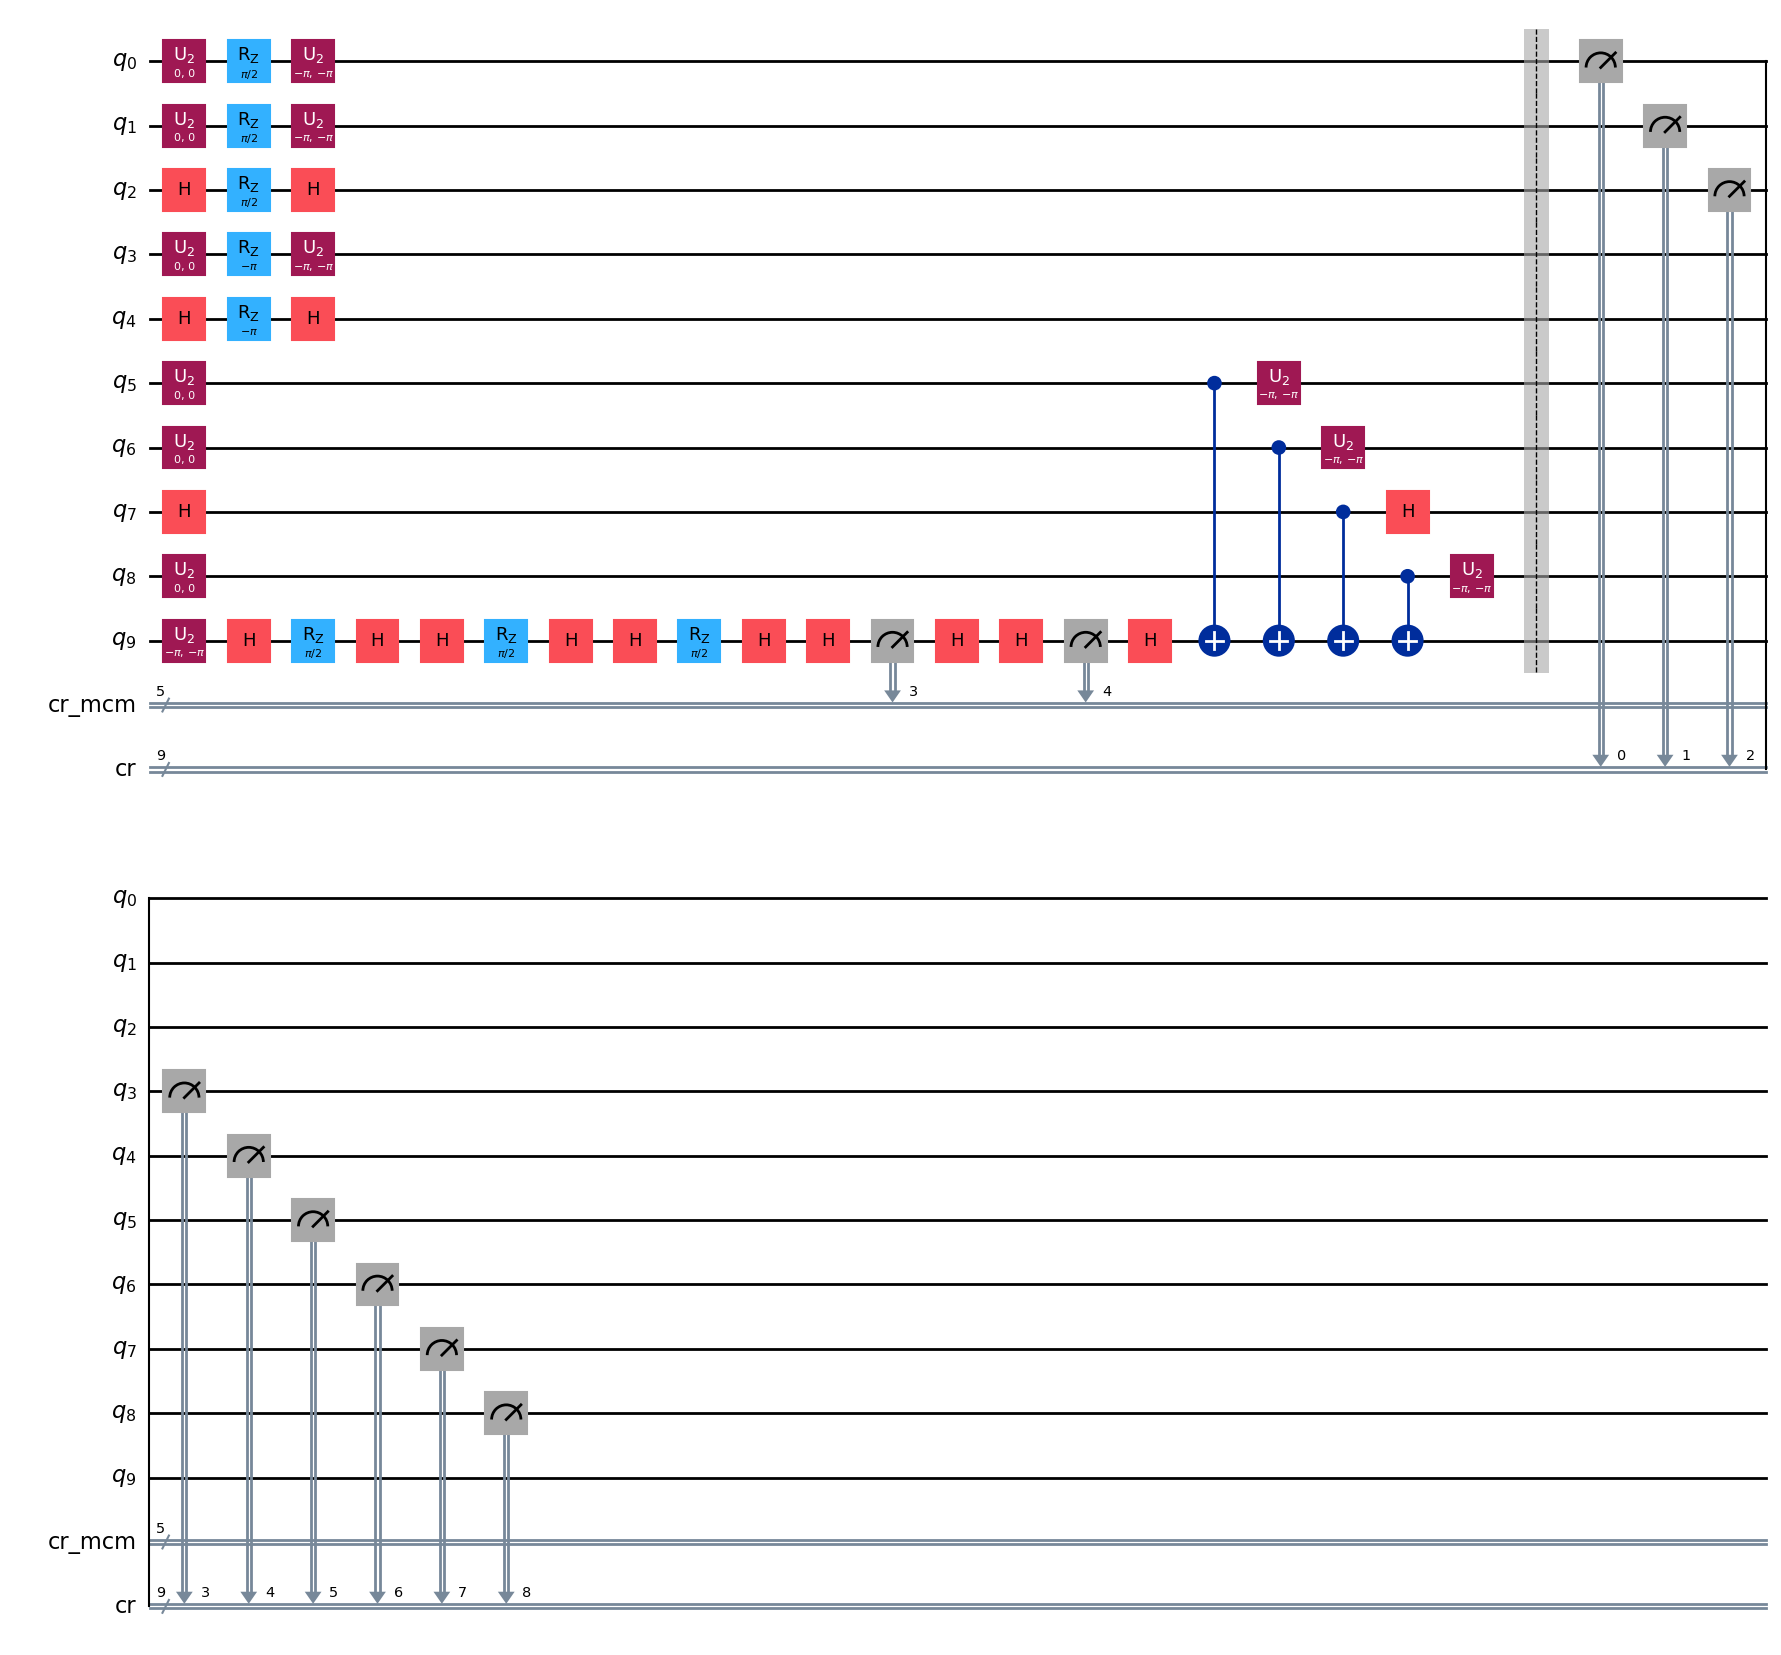

In [4]:
# Cell 4: Replace all K cross-partition CNOT gates in the Deutsch-Jozsa circuit
# with the 6-channel virtual CNOT gadget, generating all 6^K local sub-circuits
# and computing the product of QPD weights (gamma_c0 * gamma_c1 * ...) for each circuit.

def build_qpd_circuits_for_dj(qc_orig, partition_map):
    #Count how many 2-qubit gates cross partitions (K)
    num_cuts = sum(
        1 for inst in qc_orig.data
        if len(inst.qubits) == 2
        and partition_map[qc_orig.find_bit(inst.qubits[0]).index] != partition_map[qc_orig.find_bit(inst.qubits[1]).index]
    )

    qpd_circuits = []
    qpd_weights = []
    channel_tuples = list(product(range(6), repeat=num_cuts)) # All 6^K tuples (c_0, ..., c_{K-1})

    for c_tuple in channel_tuples:
        qr = QuantumRegister(qc_orig.num_qubits, 'q')
        cr_mcm = ClassicalRegister(num_cuts, 'cr_mcm')      # 1 MCM bit per cut
        cr_out = ClassicalRegister(qc_orig.num_clbits, 'cr') # Final readout bits
        qc_sub = QuantumCircuit(qr, cr_mcm, cr_out)

        cut_idx = 0
        weight = 1.0

        for inst in qc_orig.data:
            op_name = inst.operation.name
            qubits = [qc_orig.find_bit(q).index for q in inst.qubits]

            if op_name == 'measure':
                cl_idx = qc_orig.find_bit(inst.clbits[0]).index
                qc_sub.measure(qr[qubits[0]], cr_out[cl_idx])
            elif len(qubits) == 2 and partition_map[qubits[0]] != partition_map[qubits[1]]:
                #Cross-partition CNOT -> replace with channel c_tuple[cut_idx]
                c_choice = c_tuple[cut_idx]
                insert_virtual_cnot(qc_sub, qubits[0], qubits[1], cr_mcm[cut_idx], c_choice)
                weight *= QPD_COEFFS[c_choice]
                cut_idx += 1
            else:
                #Local gate (1Q gate or intra-partition CX) -> copy directly
                qc_sub.append(inst.operation, [qr[q] for q in qubits])

        qpd_circuits.append(qc_sub)
        qpd_weights.append(weight)

    return qpd_circuits, np.array(qpd_weights), channel_tuples

qpd_circuits, qpd_weights, channel_tuples = build_qpd_circuits_for_dj(dj_circuit, partition_map)
print(f"Total QPD circuits generated: {len(qpd_circuits)} (for K = {len(channel_tuples[0])} cuts)")
print(f"Sample circuit for tuple {channel_tuples[14]} (weight = {qpd_weights[14]}):")
display(qpd_circuits[14].draw(output='mpl'))

In [5]:
# Cell 5: Compute the Pauli <Z...Z> expectation value for a single QPD sub-circuit
# from its shot counts. For each bitstring, multiplies the final readout parity
# (z_total in {+1, -1}) by the mid-circuit measurement parity sign (mcm_val in {+1, -1})
# and weights by the shot probability.

def compute_expectation_from_counts(counts):
    shots = sum(counts.values())
    circuit_exp_z = 0.0

    for bitstring, count in counts.items():
        prob = count / shots
        sep = bitstring.split(' ')

        bit_out = sep[0]   # Final readout bits from cr_out
        bit_mcm = sep[1]   # Mid-circuit measurement bits from cr_mcm

        #Compute mcm_val: +1 for each '0', -1 for each '1' in bit_mcm
        mcm_val = 1
        for b in bit_mcm:
            if b == '1':
                mcm_val = mcm_val * (-1)

        #Compute z_total: product of Z eigenvalues (+1 for '0', -1 for '1') in bit_out
        z_total = 1
        for b in bit_out:
            if b == '1':
                z_total = z_total * (-1)

        #Accumulate weighted contribution for this bitstring
        circuit_exp_z += z_total * prob * mcm_val

    return circuit_exp_z

In [6]:
# Cell 6: Execute all 6^K QPD sub-circuits on an ideal (noiseless) AerSimulator
# in a single batch job and combine their expectation values using the QPD weights
# to verify that the cut circuit reproduces the uncut Deutsch-Jozsa result.

def execute_qpd_circuits(qpd_circuits, qpd_weights, shots=500):
    backend = AerSimulator()
    num_circuits = len(qpd_circuits)
    subcircuit_expectations = np.zeros(num_circuits)

    job = backend.run(qpd_circuits, shots=shots)
    result = job.result()

    for i in range(num_circuits):
        counts = result.get_counts(i)
        subcircuit_expectations[i] = compute_expectation_from_counts(counts)

    reconstructed_expectation = 0.0
    for i in range(num_circuits):
        reconstructed_expectation += qpd_weights[i] * subcircuit_expectations[i]

    return reconstructed_expectation, subcircuit_expectations

qpd_exp_val, sub_exps = execute_qpd_circuits(qpd_circuits, qpd_weights, shots=1000)
print("QPD Reconstructed Expectation Value <Z...Z>:", round(qpd_exp_val, 4))

QPD Reconstructed Expectation Value <Z...Z>: -1.0445


In [7]:
# Cell 7: Run the original uncut Deutsch-Jozsa circuit on a noiseless simulator
# to obtain the exact reference expectation value (<Z...Z>_ideal = -1.0) and check
# the absolute difference against the noiseless QPD reconstruction.

def get_ideal_dj_expectation(qc_orig, shots=10000):
    backend = AerSimulator()
    qc_transpiled = transpile(qc_orig, backend)
    job = backend.run(qc_transpiled, shots=shots)
    counts = job.result().get_counts()

    ideal_exp_z = 0.0
    for bitstring, count in counts.items():
        prob = count / shots
        #Since qc_orig has NO mid-circuit measurements, bitstring is just bit_out!
        z_total = 1
        for b in bitstring.replace(' ', ''):
            if b == '1':
                z_total = z_total * (-1)
        ideal_exp_z += z_total * prob

    return ideal_exp_z

ideal_exp_val = get_ideal_dj_expectation(dj_circuit, shots=10000)
print("Ideal Uncut DJ Expectation Value <Z...Z>   :", round(ideal_exp_val, 4))
print("QPD Reconstructed Expectation Value <Z...Z>:", round(qpd_exp_val, 4))
print("Absolute Difference (|QPD - Ideal|)        :", round(abs(qpd_exp_val - ideal_exp_val), 4))

Ideal Uncut DJ Expectation Value <Z...Z>   : -1.0
QPD Reconstructed Expectation Value <Z...Z>: -1.0445
Absolute Difference (|QPD - Ideal|)        : 0.0445


In [11]:
# Cell 8: Build the Qiskit Aer NoiseModel for the distributed QPD setup.
# Applies depolarizing error `p_local` to all local 1-qubit (h, x, rz, u1, u2, u3)
# and intra-partition 2-qubit (cx) gates, and applies amplified error
# `p_comm = alpha * p_local` to the mid-circuit measurement cut markers ('id').

QPD_COEFFS = [0.5, 0.5, -0.5, 0.5, -0.5, 0.5]

def insert_virtual_cnot(qc, q_c, q_t, mcm_clbit, c):
    if c == 0:
        qc.h(q_t)
        qc.rz(np.pi / 2, q_c)
        qc.rz(np.pi / 2, q_t)
        qc.h(q_t)
    elif c == 1:
        qc.h(q_t)
        qc.rz(-np.pi / 2, q_c)
        qc.rz(-np.pi / 2, q_t)
        qc.h(q_t)
    elif c == 2:
        qc.h(q_t)
        qc.id(q_t)                   #Injects p_comm = alpha * p_local on q_t for this MCM!
        qc.measure(q_t, mcm_clbit)
        qc.rz(-np.pi, q_c)
        qc.h(q_t)
    elif c == 3:
        qc.h(q_t)
        qc.id(q_t)                   #Injects p_comm = alpha * p_local on q_t for this MCM!
        qc.measure(q_t, mcm_clbit)
        qc.rz(0, q_c)
        qc.h(q_t)
    elif c == 4:
        qc.h(q_t)
        qc.id(q_c)                   #Injects p_comm = alpha * p_local on q_c for this MCM!
        qc.measure(q_c, mcm_clbit)
        qc.rz(-np.pi, q_t)
        qc.h(q_t)
    elif c == 5:
        qc.h(q_t)
        qc.id(q_c)                   #Injects p_comm = alpha * p_local on q_c for this MCM!
        qc.measure(q_c, mcm_clbit)
        qc.rz(0, q_t)
        qc.h(q_t)
qpd_circuits, qpd_weights, channel_tuples = build_qpd_circuits_for_dj(dj_circuit, partition_map)

In [12]:
# Cell 9: Execute all 6^K QPD sub-circuits under the noisy simulator (with
# optimization_level=0 so transpilation preserves the 'id' noise markers) and
# calculate the unmitigated baseline expectation error E_baseline = |<O>_noisy - <O>_ideal|.

from qiskit_aer.noise import NoiseModel, depolarizing_error

def build_qpd_noise_model(p_local, alpha):
    #Initialize an empty Qiskit Aer NoiseModel object
    noise_model = NoiseModel()

    #Compute the amplified error probability for the mid-circuit measurement cuts
    p_comm = alpha * p_local

    #Create the three depolarizing error channels
    error_1q_local = depolarizing_error(p_local, 1)
    error_2q_local = depolarizing_error(p_local, 2)
    error_mcm_cut  = depolarizing_error(p_comm, 1)

    #Attach each error channel to its corresponding gates across all qubits
    noise_model.add_all_qubit_quantum_error(error_1q_local, ['h', 'x', 'rz', 'u1', 'u2', 'u3'])
    noise_model.add_all_qubit_quantum_error(error_2q_local, ['cx'])
    noise_model.add_all_qubit_quantum_error(error_mcm_cut,  ['id'])

    return noise_model

In [13]:
# Cell 10: Define the unitary gate folding routines (G -> G * G_dagger * G) across
# noise scale factors lambda in [1.0, 1.5, 2.0, 2.5, 3.0]:
# - fold_circuit_global: Folds local unitary gates on the monolithic circuit BEFORE
#   QPD cutting (leaving cross-partition CNOTs unmitigated).
# - fold_circuit_local: Folds local unitary gates independently within each QPU
#   partition AFTER QPD cutting (which also mitigates the local H and Rz cut gates).

def execute_qpd_circuits_noisy(qpd_circuits, qpd_weights, noise_model, shots=50000):
    #Create the simulator with our custom noise_model attached
    backend = AerSimulator(noise_model=noise_model)
    num_circuits = len(qpd_circuits)
    subcircuit_expectations = np.zeros(num_circuits)

    #Transpile all QPD circuits with optimization_level=0 so Qiskit keeps our 'id' gates!
    transpiled_circuits = transpile(qpd_circuits, backend, optimization_level=0)

    #Run all circuits on the noisy simulator (the paper uses shots=200)
    job = backend.run(transpiled_circuits, shots=shots)
    result = job.result()

    #Loop through every single circuit i, get its counts, and compute its expectation value
    for i in range(num_circuits):
        counts_i = result.get_counts(i)
        subcircuit_expectations[i] = compute_expectation_from_counts(counts_i)

    #Multiply each circuit's expectation value by its QPD weight and sum them all up
    reconstructed_expectation = 0.0
    for i in range(num_circuits):
        reconstructed_expectation += qpd_weights[i] * subcircuit_expectations[i]

    return reconstructed_expectation, subcircuit_expectations

p_local = 0.005
alpha = 1.2
noise_model = build_qpd_noise_model(p_local, alpha)

noisy_qpd_exp, noisy_sub_exps = execute_qpd_circuits_noisy(
    qpd_circuits,
    qpd_weights,
    noise_model=noise_model,
    shots=1000
)

#Equation 1 from the paper: E_baseline = | <O>_measured - <O>_ideal | (without ZNE)
E_baseline = abs(noisy_qpd_exp - ideal_exp_val)

print("Ideal Uncut Expectation Value <Z...Z> :", round(ideal_exp_val, 4))
print("Noisy QPD Expectation Value <Z...Z>   :", round(noisy_qpd_exp, 4))
print("Baseline Error E_baseline (Eq. 1)     :", round(E_baseline, 4))

Ideal Uncut Expectation Value <Z...Z> : -1.0
Noisy QPD Expectation Value <Z...Z>   : -0.7525
Baseline Error E_baseline (Eq. 1)     : 0.2475


In [15]:
# Cell 11: Execute the Global ZNE pipeline. For each scale factor lambda, folds the
# monolithic circuit first, cuts it into 6^K QPD sub-circuits, evaluates the noisy
# expectation value, and linearly extrapolates <Z...Z>(lambda) to lambda = 0.

SCALE_FACTORS = [1.0, 1.5, 2.0, 2.5, 3.0]

def fold_circuit_global(qc_orig, partition_map, scale_factor):
    #Find the indices of all foldable local unitary gates in qc_orig.data
    foldable_indices = []
    for idx, inst in enumerate(qc_orig.data):
        op_name = inst.operation.name
        qubits = [qc_orig.find_bit(q).index for q in inst.qubits]

        if op_name in ['measure', 'barrier', 'id']:
            continue
        if len(qubits) == 2 and partition_map[qubits[0]] != partition_map[qubits[1]]:
            #Do NOT fold cross-partition CNOTs (non-local primitives are unmitigated)
            continue
        foldable_indices.append(idx)

    #Calculate how many gates to fold (G -> G * G_dagger * G) for this scale_factor
    num_foldable = len(foldable_indices)
    num_to_fold = int(round((scale_factor - 1.0) * num_foldable / 2.0))
    indices_to_fold = set(foldable_indices[:num_to_fold])

    #Build the new folded circuit
    qc_folded = QuantumCircuit(*qc_orig.qregs, *qc_orig.cregs)
    for idx, inst in enumerate(qc_orig.data):
        qc_folded.append(inst.operation, inst.qubits, inst.clbits)
        if idx in indices_to_fold:
            #Append G_dagger followed by G
            qc_folded.append(inst.operation.inverse(), inst.qubits, inst.clbits)
            qc_folded.append(inst.operation, inst.qubits, inst.clbits)

    return qc_folded


def fold_circuit_local(qc_sub, partition_map, scale_factor):
    #Group foldable gate indices by their QPU partition ID
    partition_gate_indices = {}
    for q, part_id in partition_map.items():
        partition_gate_indices[part_id] = []

    for idx, inst in enumerate(qc_sub.data):
        op_name = inst.operation.name
        if op_name in ['measure', 'barrier', 'id']:
            continue
        #Since qc_sub is already QPD-cut, all remaining gates act within a single partition!
        q0 = qc_sub.find_bit(inst.qubits[0]).index
        part_id = partition_map[q0]
        partition_gate_indices[part_id].append(idx)

    #For EACH partition independently, select (scale_factor - 1)/2 of its gates to fold
    indices_to_fold = set()
    for part_id, gate_list in partition_gate_indices.items():
        num_part_gates = len(gate_list)
        num_to_fold = int(round((scale_factor - 1.0) * num_part_gates / 2.0))
        for gate_idx in gate_list[:num_to_fold]:
            indices_to_fold.add(gate_idx)

    #Build the locally folded QPD sub-circuit
    qc_folded = QuantumCircuit(*qc_sub.qregs, *qc_sub.cregs)
    for idx, inst in enumerate(qc_sub.data):
        qc_folded.append(inst.operation, inst.qubits, inst.clbits)
        if idx in indices_to_fold:
            qc_folded.append(inst.operation.inverse(), inst.qubits, inst.clbits)
            qc_folded.append(inst.operation, inst.qubits, inst.clbits)

    return qc_folded

In [16]:
# Cell 12: Execute the Local ZNE pipeline. Cuts the circuit into 6^K physically
# decoupled QPD sub-circuits first, folds each partition's unitary gates locally
# for each scale factor lambda, and linearly extrapolates to lambda = 0 to compare
# Global vs. Local ZNE error reduction (Equations 1-4 of the paper).

def extrapolate_linear_zne(scale_factors, noisy_expectations):
    slope, intercept = np.polyfit(scale_factors, noisy_expectations, deg=1)
    return intercept, slope


def run_global_zne(qc_orig, partition_map, noise_model, scale_factors, shots=1000):
    global_exp_by_scale = []

    for lam in scale_factors:
        #Fold the monolithic circuit FIRST at scale factor `lam`
        qc_folded = fold_circuit_global(qc_orig, partition_map, scale_factor=lam)

        #Partition/cut the folded circuit into 6^K QPD sub-circuits
        qpd_circs_lam, qpd_weights_lam, _ = build_qpd_circuits_for_dj(qc_folded, partition_map)

        #Execute all 6^K QPD sub-circuits under the noise model
        exp_lam, _ = execute_qpd_circuits_noisy(
            qpd_circs_lam, qpd_weights_lam, noise_model=noise_model, shots=shots
        )
        global_exp_by_scale.append(exp_lam)
        print(f"[Global ZNE] Scale factor lambda = {lam} -> Noisy <Z...Z> = {round(exp_lam, 4)}")

    #Extrapolate to lambda = 0
    zne_global_val, _ = extrapolate_linear_zne(scale_factors, global_exp_by_scale)
    return zne_global_val, global_exp_by_scale

zne_global_exp, global_scale_exps = run_global_zne(
    dj_circuit, partition_map, noise_model, SCALE_FACTORS, shots=1000
)
E_ZNE_global = abs(zne_global_exp - ideal_exp_val)
print("\nGlobal ZNE Mitigated Expectation <Z...Z> :", round(zne_global_exp, 4))
print("Global ZNE Error (E_ZNE_global, Eq. 2)   :", round(E_ZNE_global, 4))

[Global ZNE] Scale factor lambda = 1.0 -> Noisy <Z...Z> = -0.9203
[Global ZNE] Scale factor lambda = 1.5 -> Noisy <Z...Z> = -0.7858
[Global ZNE] Scale factor lambda = 2.0 -> Noisy <Z...Z> = -0.7924
[Global ZNE] Scale factor lambda = 2.5 -> Noisy <Z...Z> = -0.6309
[Global ZNE] Scale factor lambda = 3.0 -> Noisy <Z...Z> = -0.616

Global ZNE Mitigated Expectation <Z...Z> : -1.0545
Global ZNE Error (E_ZNE_global, Eq. 2)   : 0.0545


In [19]:
# Cell 13: Evaluate the circuit depth overhead (d_ZNE / d_original, Equation 5 of
# the paper), ancilla qubit overhead (0 extra qubits for QPD), and relative error
# reduction across both individual (lambda=1) and shared baselines.


def run_local_zne(qc_orig, partition_map, noise_model, scale_factors, shots=1000):
    local_exp_by_scale = []

    #Cut the circuit FIRST into 6^K local QPD sub-circuits
    base_qpd_circuits, qpd_weights, _ = build_qpd_circuits_for_dj(qc_orig, partition_map)

    for lam in scale_factors:
        #Fold each QPD sub-circuit locally per partition at scale factor `lam`
        folded_qpd_circuits = []
        for qc_sub in base_qpd_circuits:
            qc_sub_folded = fold_circuit_local(qc_sub, partition_map, scale_factor=lam)
            folded_qpd_circuits.append(qc_sub_folded)

        # Step 3: Execute the locally folded QPD sub-circuits under the noise model
        exp_lam, _ = execute_qpd_circuits_noisy(
            folded_qpd_circuits, qpd_weights, noise_model=noise_model, shots=shots
        )
        local_exp_by_scale.append(exp_lam)
        print(f"[Local ZNE]  Scale factor lambda = {lam} -> Noisy <Z...Z> = {round(exp_lam, 4)}")

    #Extrapolate to lambda = 0
    zne_local_val, _ = extrapolate_linear_zne(scale_factors, local_exp_by_scale)
    return zne_local_val, local_exp_by_scale

zne_local_exp, local_scale_exps = run_local_zne(
    dj_circuit, partition_map, noise_model, SCALE_FACTORS, shots=1000
)
E_ZNE_local = abs(zne_local_exp - ideal_exp_val)

#Use lambda = 1.0 from Global ZNE (or your Phase 3 run) as E_baseline
E_baseline = abs(global_scale_exps[0] - ideal_exp_val)
error_reduction_global = (E_baseline - E_ZNE_global) / E_baseline
error_reduction_local  = (E_baseline - E_ZNE_local) / E_baseline

print("\n=== FINAL COMPARISON (Equations 1 - 4 of Paper) ===")
print(f"Baseline Error (E_baseline, no ZNE) : {round(E_baseline, 4)}")
print(f"Global ZNE Error (E_ZNE_global)     : {round(E_ZNE_global, 4)} | Error Reduction: {round(error_reduction_global * 100, 2)}%")
print(f"Local ZNE Error  (E_ZNE_local)      : {round(E_ZNE_local, 4)}  | Error Reduction: {round(error_reduction_local * 100, 2)}%")

[Local ZNE]  Scale factor lambda = 1.0 -> Noisy <Z...Z> = -0.889
[Local ZNE]  Scale factor lambda = 1.5 -> Noisy <Z...Z> = -0.6617
[Local ZNE]  Scale factor lambda = 2.0 -> Noisy <Z...Z> = -0.6234
[Local ZNE]  Scale factor lambda = 2.5 -> Noisy <Z...Z> = -0.7204
[Local ZNE]  Scale factor lambda = 3.0 -> Noisy <Z...Z> = -0.5034

=== FINAL COMPARISON (Equations 1 - 4 of Paper) ===
Baseline Error (E_baseline, no ZNE) : 0.0797
Global ZNE Error (E_ZNE_global)     : 0.0545 | Error Reduction: 31.61%
Local ZNE Error  (E_ZNE_local)      : 0.0354  | Error Reduction: 55.56%


In [21]:
# Cell 14: Plot the Global vs. Local ZNE linear extrapolation fits from lambda in
# [1.0 .. 3.0] back to the zero-noise limit (lambda = 0) alongside a bar chart
# comparing unmitigated baseline error against Global and Local ZNE errors.d_original = dj_circuit.depth()

n_qubits_original = dj_circuit.num_qubits

#Compute average circuit depth across the 5 ZNE scale factors for Global ZNE and Local ZNE
global_depths_by_scale = []
local_depths_by_scale = []

#Pre-build base QPD circuits once to measure Local ZNE depths quickly
base_qpd_circuits, _, _ = build_qpd_circuits_for_dj(dj_circuit, partition_map)

for lam in SCALE_FACTORS:
    #Global ZNE depth at scale factor `lam` (sample first QPD branch c_tuple = (0,0,0,0,0))
    qc_glob_folded = fold_circuit_global(dj_circuit, partition_map, scale_factor=lam)
    qpd_glob_sample, _, _ = build_qpd_circuits_for_dj(qc_glob_folded, partition_map)
    global_depths_by_scale.append(qpd_glob_sample[0].depth())

    #Local ZNE depth at scale factor `lam` (sample first QPD branch c_tuple = (0,0,0,0,0))
    qc_loc_folded = fold_circuit_local(base_qpd_circuits[0], partition_map, scale_factor=lam)
    local_depths_by_scale.append(qc_loc_folded.depth())

#Equation (5) from the paper: Depth Overhead = d_ZNE / d_original
d_zne_global = np.mean(global_depths_by_scale)
d_zne_local  = np.mean(local_depths_by_scale)

depth_overhead_global = d_zne_global / d_original
depth_overhead_local  = d_zne_local / d_original

#Compute Error Reduction using each method's own lambda=1.0 baseline AND shared baseline
E_base_global_lam1 = abs(global_scale_exps[0] - ideal_exp_val)
E_base_local_lam1  = abs(local_scale_exps[0] - ideal_exp_val)
E_base_shared      = (E_base_global_lam1 + E_base_local_lam1) / 2.0

err_red_global_own    = (E_base_global_lam1 - E_ZNE_global) / E_base_global_lam1
err_red_local_own     = (E_base_local_lam1 - E_ZNE_local) / E_base_local_lam1
err_red_global_shared = (E_base_shared - E_ZNE_global) / E_base_shared
err_red_local_shared  = (E_base_shared - E_ZNE_local) / E_base_shared

print(f"Original DJ Qubits : {n_qubits_original}, QPD Qubits : {base_qpd_circuits[0].num_qubits} (Ancilla Overhead = 0 qubits!)")
print(f"Original DJ Depth  : {d_original}")
print(f"Global ZNE Depths across {SCALE_FACTORS}: {global_depths_by_scale} -> Mean Depth = {round(d_zne_global, 2)} (Overhead = {round(depth_overhead_global, 2)}x)")
print(f"Local ZNE Depths  across {SCALE_FACTORS}: {local_depths_by_scale} -> Mean Depth = {round(d_zne_local, 2)} (Overhead = {round(depth_overhead_local, 2)}x)")
print("-" * 65)
print(f"Global ZNE : lambda=1 Error = {round(E_base_global_lam1, 4)} -> ZNE Error = {round(E_ZNE_global, 4)} | Own Reduction = {round(err_red_global_own*100, 2)}% (Shared Base = {round(err_red_global_shared*100, 2)}%)")
print(f"Local ZNE  : lambda=1 Error = {round(E_base_local_lam1, 4)} -> ZNE Error = {round(E_ZNE_local, 4)} | Own Reduction = {round(err_red_local_own*100, 2)}% (Shared Base = {round(err_red_local_shared*100, 2)}%)")

Original DJ Qubits : 10, QPD Qubits : 10 (Ancilla Overhead = 0 qubits!)
Original DJ Depth  : 12
Global ZNE Depths across [1.0, 1.5, 2.0, 2.5, 3.0]: [22, 22, 24, 26, 34] -> Mean Depth = 25.6 (Overhead = 2.13x)
Local ZNE Depths  across [1.0, 1.5, 2.0, 2.5, 3.0]: [22, 28, 42, 56, 64] -> Mean Depth = 42.4 (Overhead = 3.53x)
-----------------------------------------------------------------
Global ZNE : lambda=1 Error = 0.0797 -> ZNE Error = 0.0545 | Own Reduction = 31.61% (Shared Base = 42.84%)
Local ZNE  : lambda=1 Error = 0.111 -> ZNE Error = 0.0354 | Own Reduction = 68.1% (Shared Base = 62.86%)


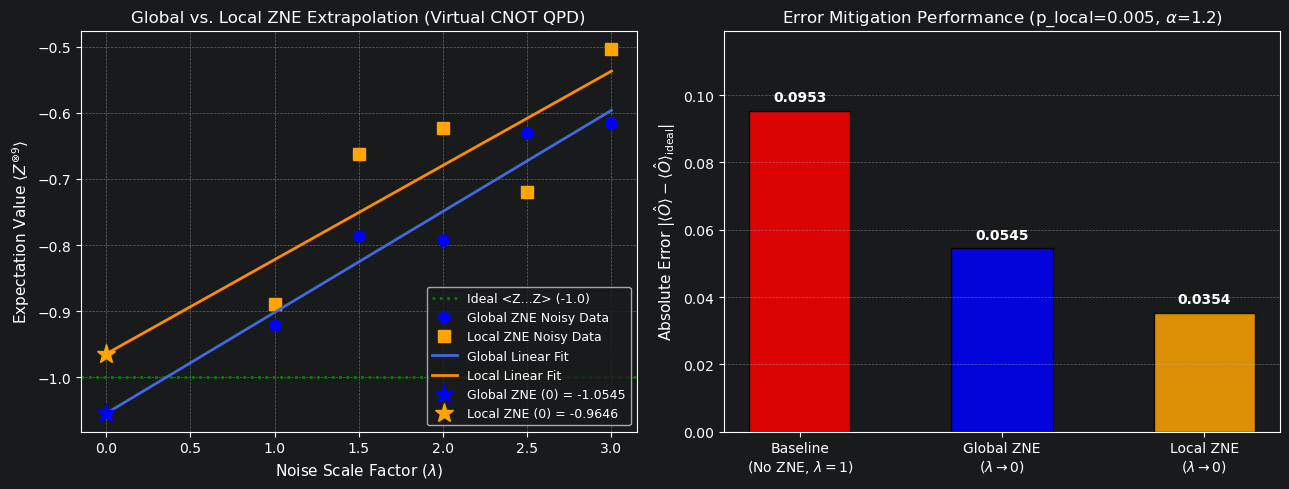

In [22]:
import matplotlib.pyplot as plt

zne_glob_intercept, zne_glob_slope = extrapolate_linear_zne(SCALE_FACTORS, global_scale_exps)
zne_loc_intercept,  zne_loc_slope  = extrapolate_linear_zne(SCALE_FACTORS, local_scale_exps)

lambda_line = np.linspace(0.0, 3.0, 100)
glob_fit_line = zne_glob_slope * lambda_line + zne_glob_intercept
loc_fit_line  = zne_loc_slope  * lambda_line + zne_loc_intercept

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.axhline(y=ideal_exp_val, color='green', linestyle=':', linewidth=2, label=f'Ideal <Z...Z> ({ideal_exp_val})')

ax1.plot(SCALE_FACTORS, global_scale_exps, 'o', color='blue', markersize=8, label='Global ZNE Noisy Data')
ax1.plot(SCALE_FACTORS, local_scale_exps,  's', color='orange', markersize=8, label='Local ZNE Noisy Data')

ax1.plot(lambda_line, glob_fit_line, color='royalblue', linewidth=2, label='Global Linear Fit')
ax1.plot(lambda_line, loc_fit_line, color='darkorange', linewidth=2, label='Local Linear Fit')

ax1.plot(0.0, zne_glob_intercept, '*', color='blue', markersize=14, label=f'Global ZNE (0) = {round(zne_glob_intercept, 4)}')
ax1.plot(0.0, zne_loc_intercept,  '*', color='orange', markersize=14, label=f'Local ZNE (0) = {round(zne_loc_intercept, 4)}')

ax1.set_xlabel('Noise Scale Factor ($\\lambda$)', fontsize=11)
ax1.set_ylabel('Expectation Value $\\langle Z^{\\otimes 9} \\rangle$', fontsize=11)
ax1.set_title('Global vs. Local ZNE Extrapolation (Virtual CNOT QPD)', fontsize=12)
ax1.set_xlim(-0.15, 3.15)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right', fontsize=9)

labels = ['Baseline\n(No ZNE, $\\lambda=1$)', 'Global ZNE\n($\\lambda \\to 0$)', 'Local ZNE\n($\\lambda \\to 0$)']
errors = [E_base_shared, E_ZNE_global, E_ZNE_local]
colors = ['red', 'blue', 'orange']

bars = ax2.bar(labels, errors, color=colors, width=0.5, edgecolor='black', alpha=0.85)

for bar in bars:
    height = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 0.002,
        f'{height:.4f}',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax2.set_ylabel('Absolute Error $|\\langle \\hat{O} \\rangle - \\langle \\hat{O} \\rangle_{\\mathrm{ideal}}|$', fontsize=11)
ax2.set_title(f'Error Mitigation Performance (p_local={p_local}, $\\alpha$={alpha})', fontsize=12)
ax2.set_ylim(0, max(errors) * 1.25)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()